In [1]:
import librosa as lr
import soundfile as sf

In [18]:
import matplotlib.pyplot as plt
import scipy as sp
import numpy as np
from IPython.display import Audio

In [2]:
file = "C:/Users/irpra/Music/dataset/music/Zack_Knight_Angel_Official_Music.mp3"
# Load an MP3 file
f, sr = lr.load(file, sr=None)  # sr=None keeps original sampling rate

# y: audio time series (numpy array)
# sr: sampling rate (e.g., 44100 Hz)   

In [22]:
# lets' have fun via listening music
Audio(f,rate=sr)

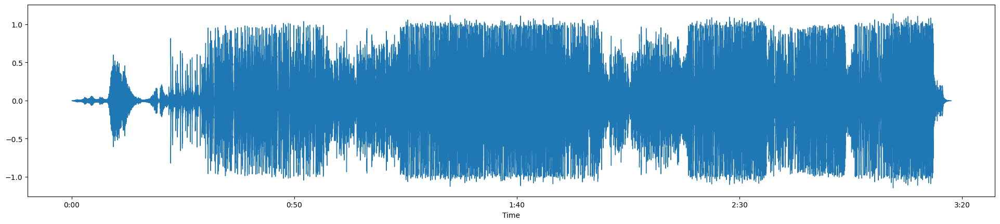

In [ ]:
# Plot : Aplitude vs Time 
# Wave form of signal
plt.figure().set_figwidth(24)
lr.display.waveshow(f, sr=sr)
plt.show()

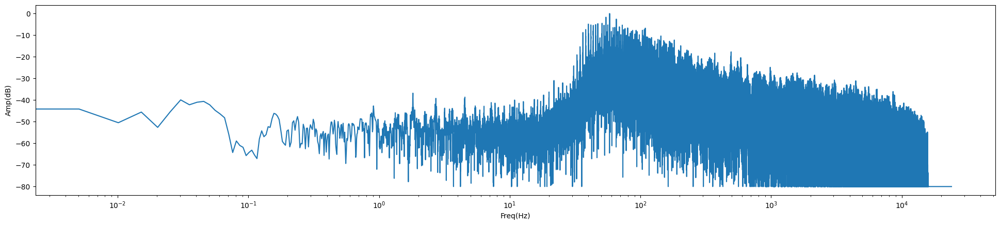

In [16]:
# Frequency spectrum of signal
# Plot : Amplitude vs Frequency

# input to dft as first 10000 sample
dft_ipt = f
# dft of signal
# The Hanning window is a taper formed by using a weighted cosine.
window = np.hanning(len(dft_ipt))
window_ipt = dft_ipt * window
dft = np.fft.rfft(window_ipt)

# amplitude spectrum in decibels
# Convert an amplitude spectrogram to dB-scaled spectrogram.
amp = np.abs(dft)
amp_db = lr.amplitude_to_db(amp, ref=np.max)

# freq bins
freq = lr.fft_frequencies(sr=sr, n_fft=len(dft_ipt))

plt.figure().set_figwidth(24)
plt.plot(freq, amp_db)
plt.xlabel('Freq(Hz)')
plt.ylabel('Amp(dB)')
plt.xscale('log')
plt.show()

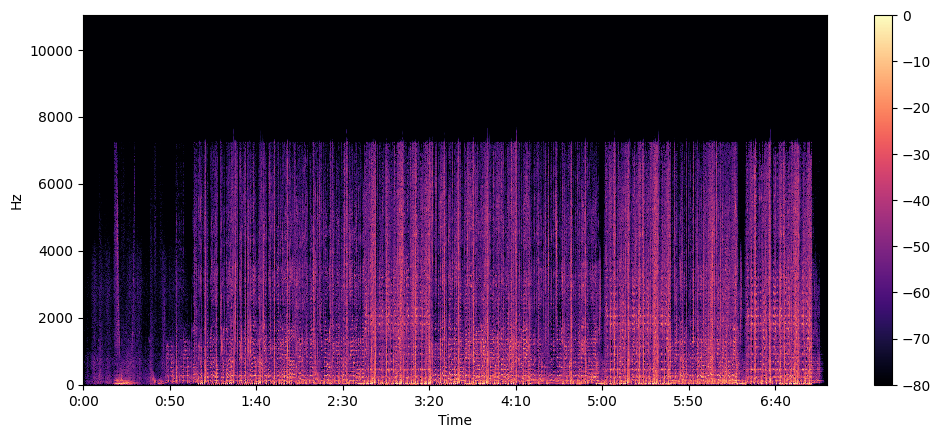

In [17]:
# Spectrogram of signal
# Plot : Freq vs Time
D = lr.stft(f)
S_db = lr.amplitude_to_db(np.abs(D), ref=np.max)

plt.figure().set_figwidth(12)
lr.display.specshow(S_db, x_axis="time", y_axis="hz")
plt.colorbar()
plt.show()

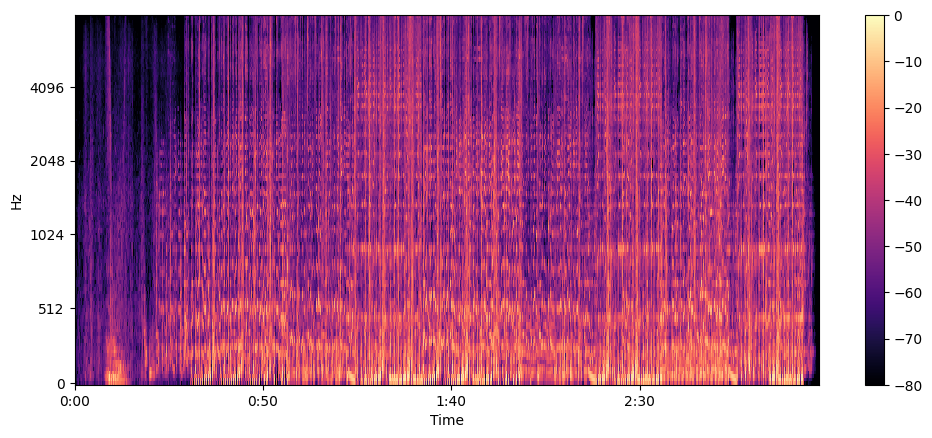

In [38]:
# MEL Spectrogram
# Plot : Non-linear frequency vs Time
S = lr.feature.melspectrogram(
    y=f,
    sr=sr,
    n_mels=128, ## nb of mel bands to generate
    fmax= 10000, # highest freq. we care about
)

S_dB = lr.power_to_db(S, ref=np.max)

plt.figure().set_figwidth(12)
lr.display.specshow(S_dB, x_axis="time", y_axis="mel", sr=sr,
                         fmax=8000)
plt.colorbar()
plt.show()


Spectral Centroid: Perceived "brightness" of sound
Spectral Rolloff: Frequency below which most energy lies
Spectral Bandwidth: Spread of the spectrum
MFCCs (Mel-Frequency Cepstral Coefficients): Represent timbre; widely used in classification
Chromagram: Pitch class content (e.g., C, C#, D) over time
Tonnetz: Harmonic relationships using music theory

In [ ]:
# 2. Extract features
tempo, beats = lr.beat.beat_track(y=f, sr=sr)
mfcc = lr.feature.mfcc(y=f, sr=sr, n_mfcc=13)
chroma = lr.feature.chroma_cqt(y=f, sr=sr)
spectral_centroid = lr.feature.spectral_centroid(y=f, sr=sr)

Tempo: [144.23076923] BPM
MFCC shape: (13, 18517)


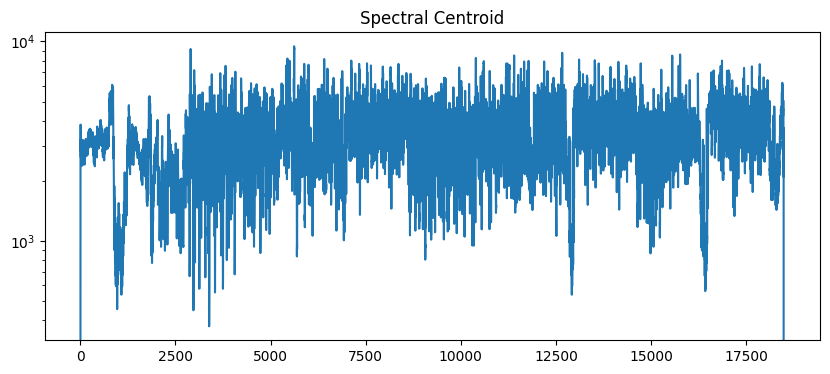

In [25]:
# 3. Display
print(f"Tempo: {tempo} BPM")
print(f"MFCC shape: {mfcc.shape}")
plt.figure(figsize=(10, 4))
plt.semilogy(spectral_centroid.T)
plt.title("Spectral Centroid")
plt.show()

1. Aggregate Features Statistically
Compute mean, standard deviation, etc., across time:

In [32]:
mfcc_mean = np.mean(mfcc, axis=1)
mfcc_std = np.std(mfcc, axis=1)   

In [28]:
# Zero-crossing rate
zcr = lr.feature.zero_crossing_rate(f)

# Spectral rolloff
rolloff = lr.feature.spectral_rolloff(y=f, sr=sr)

# Harmonic-percussive separation
y_harm, y_perc = lr.effects.hpss(f)   

In [29]:
np.save('outputs/mfcc.npy', mfcc)
# Or save all in a dictionary
data = {'mfcc': mfcc, 'tempo': tempo, 'chroma': chroma}
np.save('outputs/features.npy', data)   

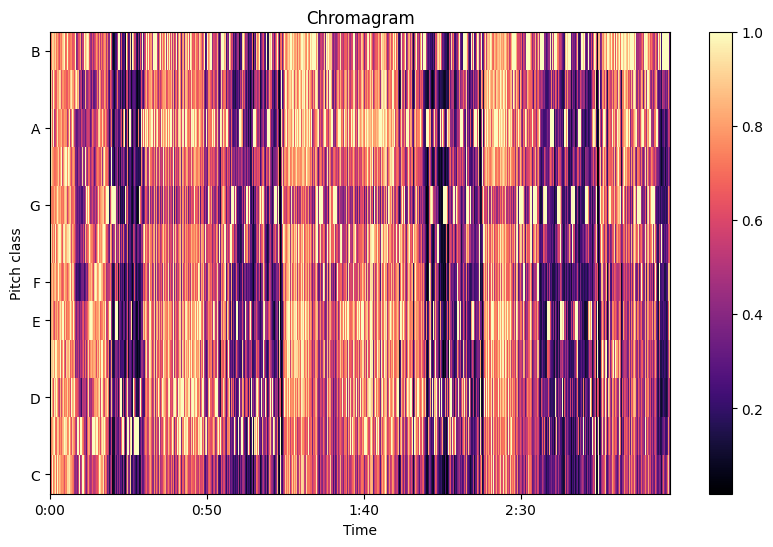

In [30]:
plt.figure(figsize=(10, 6))
lr.display.specshow(chroma, sr=sr, x_axis='time', y_axis='chroma')
plt.colorbar()
plt.title('Chromagram')
plt.show()   

MFCCs: Represent timbral texture; capture vocal/instrumental characteristics.
Chromagram: Shows pitch class activity (e.g., C, D, E); useful for harmony analysis.
Spectral Centroid: Indicates "brightness" — higher values = brighter sound.
Tempo & Beats: Reveal rhythmic structure (BPM, beat times).
Zero-Crossing Rate: Measures noisiness — high for sibilants or percussive sounds.

In [31]:
feature_vector = np.hstack([
    mfcc_mean,
    np.mean(chroma, axis=1),
    np.mean(spectral_centroid),
    tempo,
    np.mean(zcr)
])
print("Feature vector shape:", feature_vector.shape)   

Feature vector shape: (28,)


In [34]:
feature_vector[:]

array([-1.49306198e+02,  1.21942795e+02, -2.32164536e+01,  4.86028328e+01,
       -1.00515022e+01,  2.80818176e+01, -7.51324272e+00,  8.03784561e+00,
       -3.10624051e+00,  3.85641646e+00, -1.07342529e+00, -1.71528864e+00,
        6.00915480e+00,  4.99393493e-01,  5.99449277e-01,  6.15751326e-01,
        5.69343746e-01,  6.19453967e-01,  5.28941631e-01,  6.04681969e-01,
        5.68714619e-01,  5.62450290e-01,  6.57750249e-01,  5.66221356e-01,
        6.73295617e-01,  3.27526096e+03,  1.44230769e+02,  6.44783341e-02])

In [ ]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import cosine_similarity

# 1. Reshape for clustering (n_samples, n_features)
X = feature_vector.reshape(1, -1)

# 2. Compare with another song (example)
another_song = np.random.rand(28)  # Replace with real data
similarity = cosine_similarity(X, another_song.reshape(1, -1))
print(f"Similarity to another song: {similarity[0][0]:.3f}")  

Similarity to another song: 0.114
